
# AdaBoost (Adaptive Boosting)

AdaBoost, short for Adaptive Boosting, is an ensemble machine learning algorithm that combines multiple weak learners to create a strong predictive model.

It works by training a sequence of models, where each subsequent model focuses more on the observations that previous models predicted incorrectly.

Unlike Random Forest, which builds multiple decision trees independently, AdaBoost builds its learners sequentially. Each learner attempts to improve on the mistakes made by the preceding learners.

AdaBoost assigns weights to training observations. Misclassified observations receive greater emphasis during classification, while observations with larger prediction errors receive greater emphasis during regression.

The predictions from individual learners are then combined using a weighted approach to produce the final prediction.

### Key Characteristics

- **Ensemble Learning:** Combines multiple weak learners into one stronger model.
- **Sequential Training:** Models are trained one after another.
- **Adaptive Learning:** Gives greater attention to difficult observations.
- **Weighted Predictions:** Combines individual learner predictions based on their performance.
- **Versatility:** Supports both regression and classification tasks.

### Types of AdaBoost

1. **AdaBoost Regressor:** Used to predict continuous numerical values.
2. **AdaBoost Classifier:** Used to predict categorical class labels.

### Applications

- Fraud detection
- Medical diagnosis
- Credit risk assessment
- Customer churn prediction
- Predictive modelling


In [44]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score,roc_curve)
import warnings
warnings.filterwarnings('ignore')

## Regression

In [3]:
# load dataset

# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Create dataframe
housing_df = housing.frame

print(housing_df.shape)
housing_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
# Dataset shape
print("Dataset Shape:", housing_df.shape)

# Column names
print("\nColumns:")
print(housing_df.columns.tolist())

# Dataset information
housing_df.info()

Dataset Shape: (20640, 9)

Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
housing_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
# mising value
housing_df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

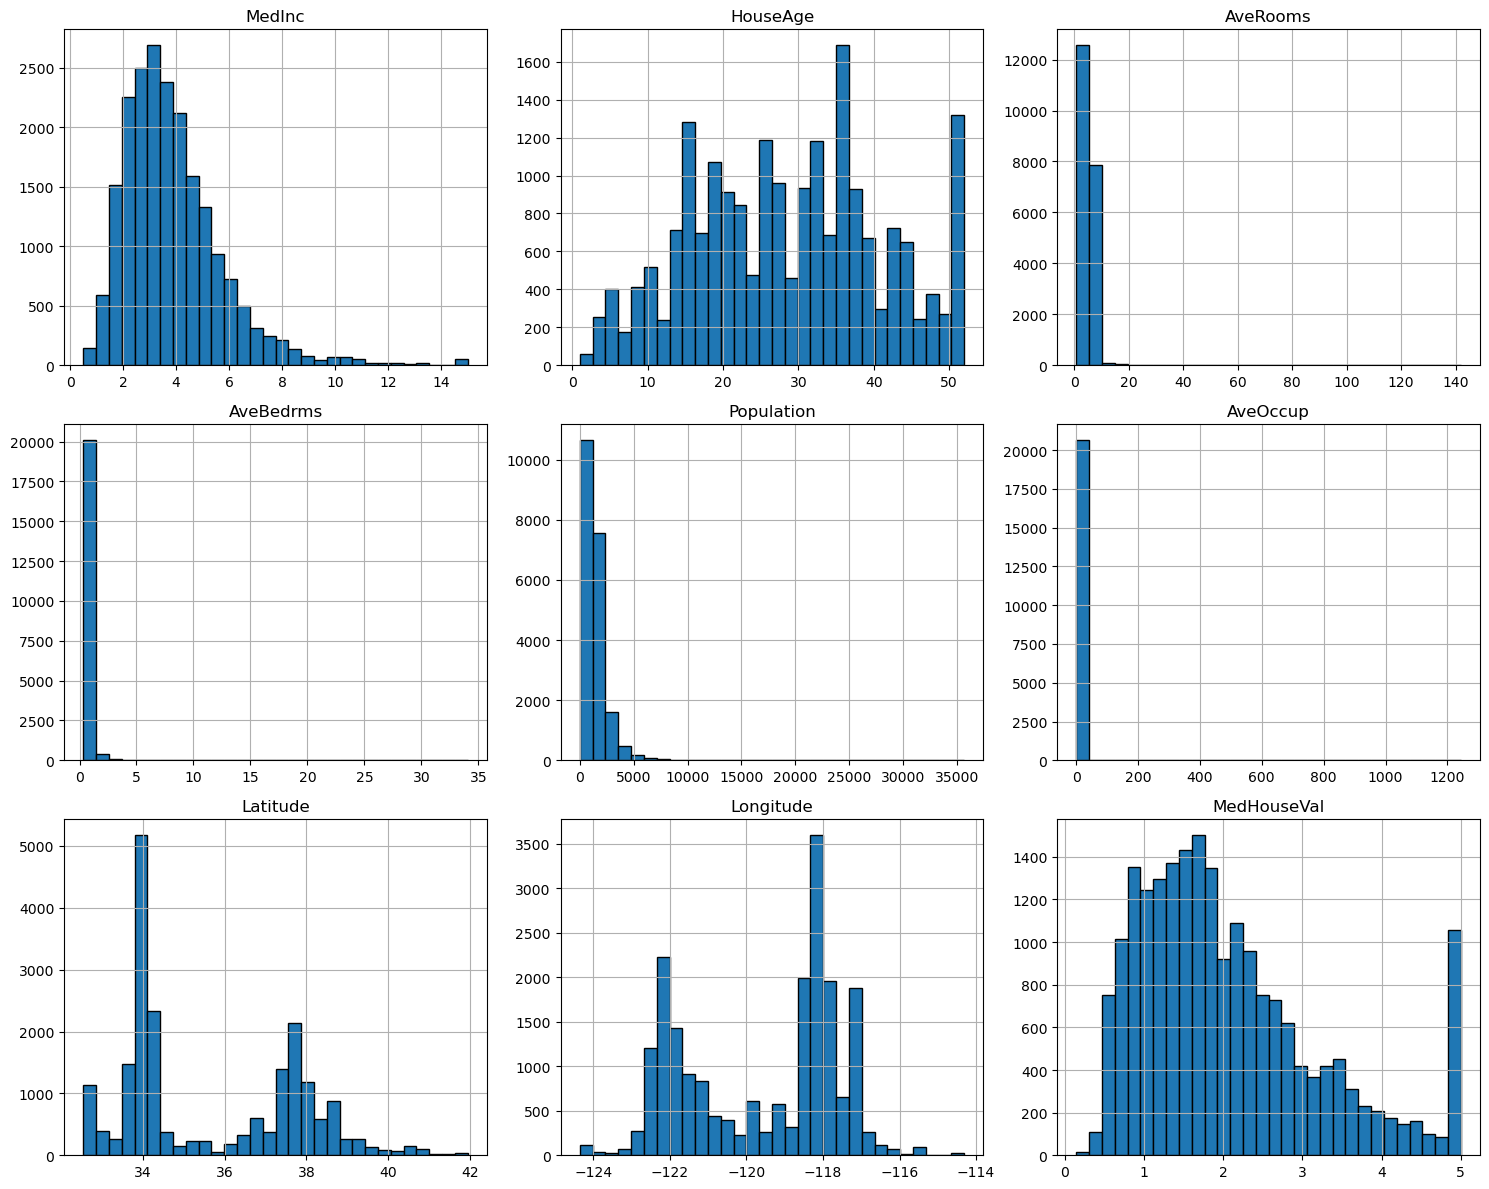

In [7]:
# numerical features distribution
housing_df.hist(figsize=(15, 12), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

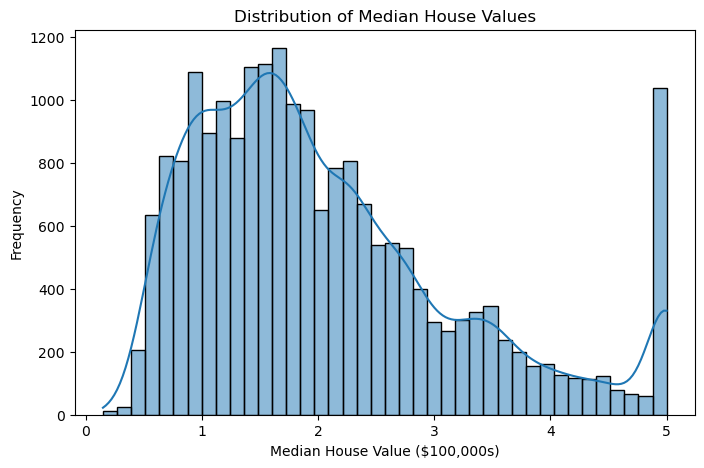

In [8]:
# target distribution
plt.figure(figsize=(8, 5))
sns.histplot(housing_df['MedHouseVal'], bins=40, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000s)")
plt.ylabel("Frequency")

plt.show()

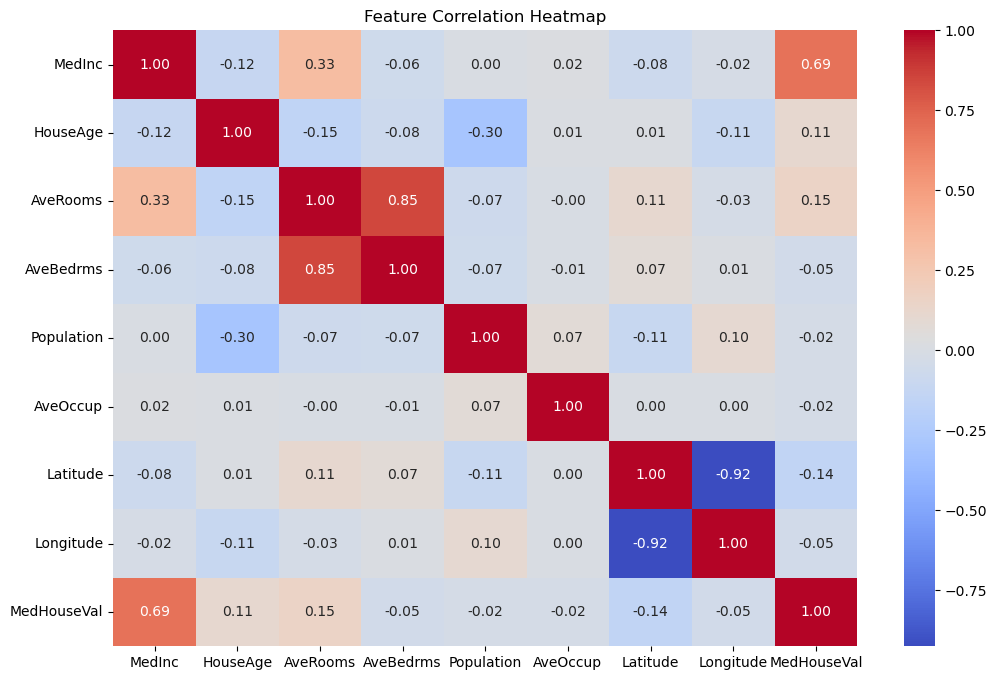

In [9]:
# Correlation analysis
plt.figure(figsize=(12, 8))

sns.heatmap(housing_df.corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title("Feature Correlation Heatmap")
plt.show()


In [10]:
# Preprocessing
# Separate features and target
X = housing_df.drop('MedHouseVal', axis=1)
y = housing_df['MedHouseVal']

# dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (20640, 8)
Target shape: (20640,)


In [11]:
# split- train
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


In [12]:

# training data
print(X_train.head())
# testing data
X_test.head()


       MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
14196  3.2596      33.0  5.017657   1.006421      2300.0  3.691814     32.71   
8267   3.8125      49.0  4.473545   1.041005      1314.0  1.738095     33.77   
17445  4.1563       4.0  5.645833   0.985119       915.0  2.723214     34.66   
14265  1.9425      36.0  4.002817   1.033803      1418.0  3.994366     32.69   
2271   3.5542      43.0  6.268421   1.134211       874.0  2.300000     36.78   

       Longitude  
14196    -117.03  
8267     -118.16  
17445    -120.48  
14265    -117.11  
2271     -119.80  


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01
3024,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46
15663,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44
20484,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72
9814,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93


In [13]:
# target distribution
print("Training target summary:")
print(y_train.describe())

print("\nTesting target summary:")
print(y_test.describe())


Training target summary:
count    16512.000000
mean         2.071947
std          1.156226
min          0.149990
25%          1.198000
50%          1.798500
75%          2.651250
max          5.000010
Name: MedHouseVal, dtype: float64

Testing target summary:
count    4128.000000
mean        2.055003
std         1.144870
min         0.149990
25%         1.192750
50%         1.786500
75%         2.630000
max         5.000010
Name: MedHouseVal, dtype: float64


In [14]:
# Modelling
# Initialize AdaBoost Regressor
ada_reg = AdaBoostRegressor(random_state=42)

# Train the model
ada_reg.fit(X_train, y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,loss,'linear'
,random_state,42


In [15]:
# Training predictions
y_train_pred = ada_reg.predict(X_train)

# Testing predictions
y_test_pred = ada_reg.predict(X_test)

In [16]:
# Training evaluation
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)

# Testing evaluation
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

# Display results
print("Training Performance")
print("MAE:", train_mae)
print("MSE:", train_mse)
print("RMSE:", train_rmse)
print("R2 Score:", train_r2)

print("\nTesting Performance")
print("MAE:", test_mae)
print("MSE:", test_mse)
print("RMSE:", test_rmse)
print("R2 Score:", test_r2)


Training Performance
MAE: 0.648440953106919
MSE: 0.6043219253973799
RMSE: 0.7773814542406964
R2 Score: 0.5479265594937941

Testing Performance
MAE: 0.6497879664773323
MSE: 0.614478459432694
RMSE: 0.7838867644198962
R2 Score: 0.5310788695468394


In [17]:
# Actual vs. predicted

ada_reg_results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_test_pred
})

ada_reg_results.head(10)

,Actual Values,Predicted Values
0,0.47700,1.505219
1,0.45800,1.667222
2,5.00001,3.191081
3,2.18600,2.650912
4,2.78000,2.443085
5,1.58700,2.443085
6,1.98200,2.712972
7,1.57500,2.443085
8,3.40000,3.281641
9,4.46600,4.241122


In [18]:
# feature importance

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': ada_reg.feature_importances_
}).sort_values(by='Importance', ascending=False)

feature_importance

,Feature,Importance
0,MedInc,0.420941
7,Longitude,0.159352
6,Latitude,0.146282
5,AveOccup,0.125988
2,AveRooms,0.060222
1,HouseAge,0.040109
4,Population,0.029541
3,AveBedrms,0.017566


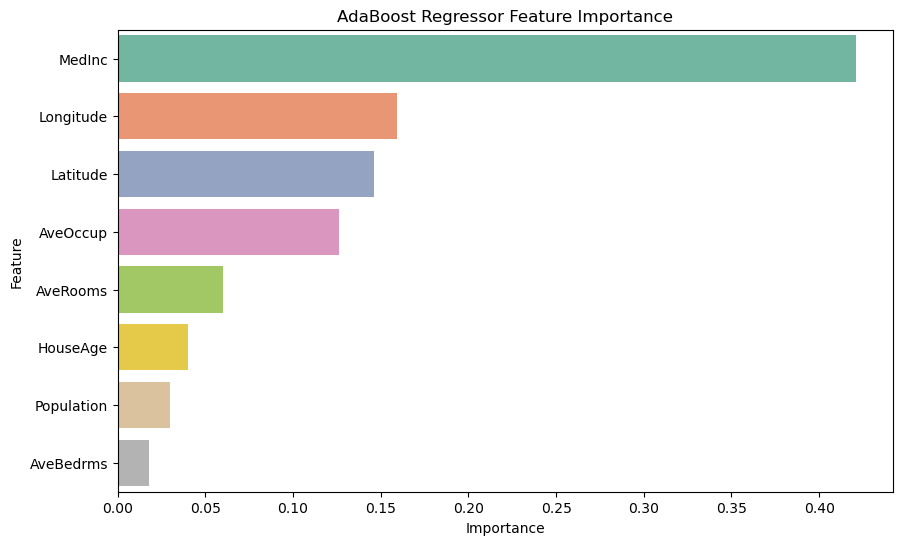

In [19]:
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance,x='Importance',y='Feature',palette='Set2')
plt.title("AdaBoost Regressor Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [20]:

#  parameter grid
param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.1, 0.5, 1.0],
    'loss': ['linear', 'square', 'exponential']
}

ada_grid = GridSearchCV(estimator=AdaBoostRegressor(random_state=42),param_grid=param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
# Perform hyperparameter tuning
ada_grid.fit(X_train, y_train)

print("Best Parameters:", ada_grid.best_params_)
print("Best Cross-Validation R2 Score:", ada_grid.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters: {'learning_rate': 0.1, 'loss': 'exponential', 'n_estimators': 50}
Best Cross-Validation R2 Score: 0.5892329348807679


In [21]:
# Retrieve best model
ada_reg_tuned = ada_grid.best_estimator_

# Predictions
y_train_pred_tuned = ada_reg_tuned.predict(X_train)
y_test_pred_tuned = ada_reg_tuned.predict(X_test)

In [22]:
# Training metrics
print("Tuned Training Performance")
print("MAE:", mean_absolute_error(y_train, y_train_pred_tuned))
print("MSE:", mean_squared_error(y_train, y_train_pred_tuned))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred_tuned)))
print("R2 Score:", r2_score(y_train, y_train_pred_tuned))

# Testing metrics
print("\nTuned Testing Performance")
print("MAE:", mean_absolute_error(y_test, y_test_pred_tuned))
print("MSE:", mean_squared_error(y_test, y_test_pred_tuned))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred_tuned)))
print("R2 Score:", r2_score(y_test, y_test_pred_tuned))

Tuned Training Performance
MAE: 0.5729152716210477
MSE: 0.5394522026718163
RMSE: 0.7344740993880018
R2 Score: 0.5964534745448169

Tuned Testing Performance
MAE: 0.5801608691068713
MSE: 0.5589103214629432
RMSE: 0.7476030507314314
R2 Score: 0.5734840567002009


In [23]:
# Compare original and tuned models
ada_comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],

    'Original Model': [
        mean_absolute_error(y_test, y_test_pred),
        mean_squared_error(y_test, y_test_pred),
        np.sqrt(mean_squared_error(y_test, y_test_pred)),
        r2_score(y_test, y_test_pred)
    ],

    'Tuned Model': [
        mean_absolute_error(y_test, y_test_pred_tuned),
        mean_squared_error(y_test, y_test_pred_tuned),
        np.sqrt(mean_squared_error(y_test, y_test_pred_tuned)),
        r2_score(y_test, y_test_pred_tuned)
    ]
})

ada_comparison


,Metric,Original Model,Tuned Model
0,MAE,0.649788,0.580161
1,MSE,0.614478,0.558910
2,RMSE,0.783887,0.747603
3,R2 Score,0.531079,0.573484


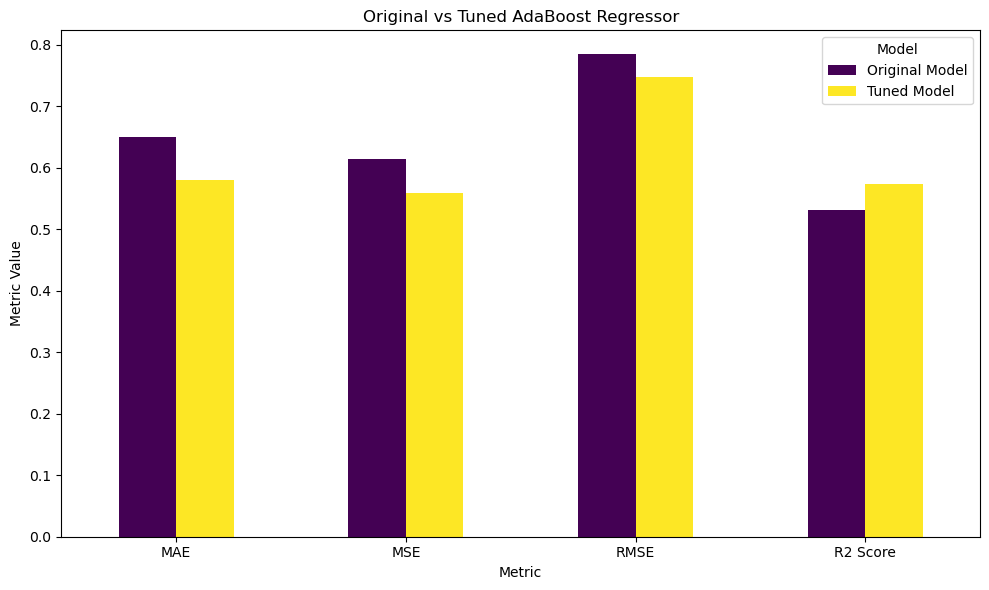

In [24]:
ada_comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(10, 6),
    colormap='viridis'
)

plt.title("Original vs Tuned AdaBoost Regressor")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


## Classification

### Iris

In [60]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
# define ADABoost class
class AdaBoost:
    def __init__(self, n_estimators=50):
        self.n_estimators = n_estimators
        self.alphas = []
        self.models = []

In [61]:
# train model
def fit(self, X, y):
        n_samples, n_features = X.shape  
        w = np.ones(n_samples) / n_samples 

        for _ in range(self.n_estimators):
            model = DecisionTreeClassifier(max_depth=1)  
            model.fit(X, y, sample_weight=w)  
            predictions = model.predict(X)  

            err = np.sum(w * (predictions != y)) / np.sum(w)

            alpha = 0.5 * np.log((1 - err) / (err + 1e-10))

            self.models.append(model) 
            self.alphas.append(alpha)  

            w *= np.exp(-alpha * y * predictions)  
            w /= np.sum(w)

In [62]:
# prediction
def predict(self, X):
        strong_preds = np.zeros(X.shape[0])  

        for model, alpha in zip(self.models, self.alphas):
            predictions = model.predict(X)  
            strong_preds += alpha * predictions  

        return np.sign(strong_preds).astype(int)

In [66]:

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


if __name__ == "__main__":

    # Generate synthetic classification dataset
    X, y = make_classification(n_samples=1000,n_features=20,n_classes=2,random_state=42)

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.3,random_state=42,stratify=y)

    # Initialize AdaBoost Classifier
    adaboost = AdaBoostClassifier(n_estimators=50,random_state=42)

    # Train model
    adaboost.fit(X_train, y_train)

    # Make predictions
    predictions = adaboost.predict(X_test)

    # Prediction probabilities
    probabilities = adaboost.predict_proba(X_test)[:, 1]

    # Evaluate model
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)
    roc_auc = roc_auc_score(y_test, probabilities)

    # Display results
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")

Accuracy: 84.67%
Precision: 0.8421
Recall: 0.8533
F1 Score: 0.8477
ROC-AUC: 0.9185


### Cancer dataset

In [25]:
# load dataset
from sklearn.datasets import load_breast_cancer
# Load Breast Cancer dataset
cancer = load_breast_cancer(as_frame=True)

# Create DataFrame
cancer_df = cancer.frame
print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [26]:
# Column names
print("\nColumns:")
print(cancer_df.columns.tolist())

# Dataset information
cancer_df.info()


Columns:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area               

In [27]:
# missing values
cancer_df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [28]:
# duplicates
cancer_df.duplicated().sum()

np.int64(0)

In [29]:
# target distribution
cancer_df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

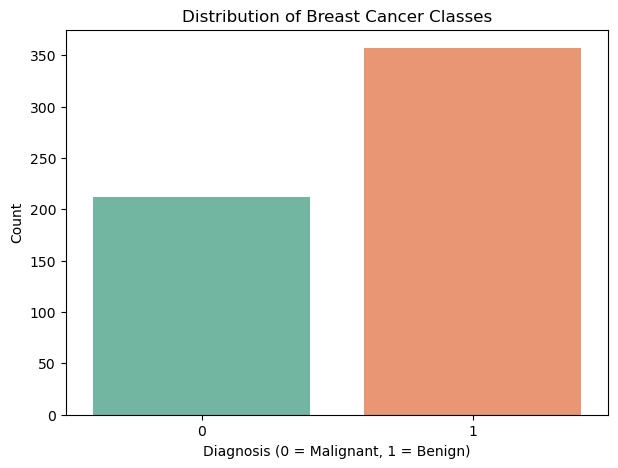

In [30]:

plt.figure(figsize=(7, 5))
sns.countplot(data=cancer_df,x='target',hue='target',palette='Set2',legend=False)
plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Diagnosis (0 = Malignant, 1 = Benign)")
plt.ylabel("Count")

plt.show()


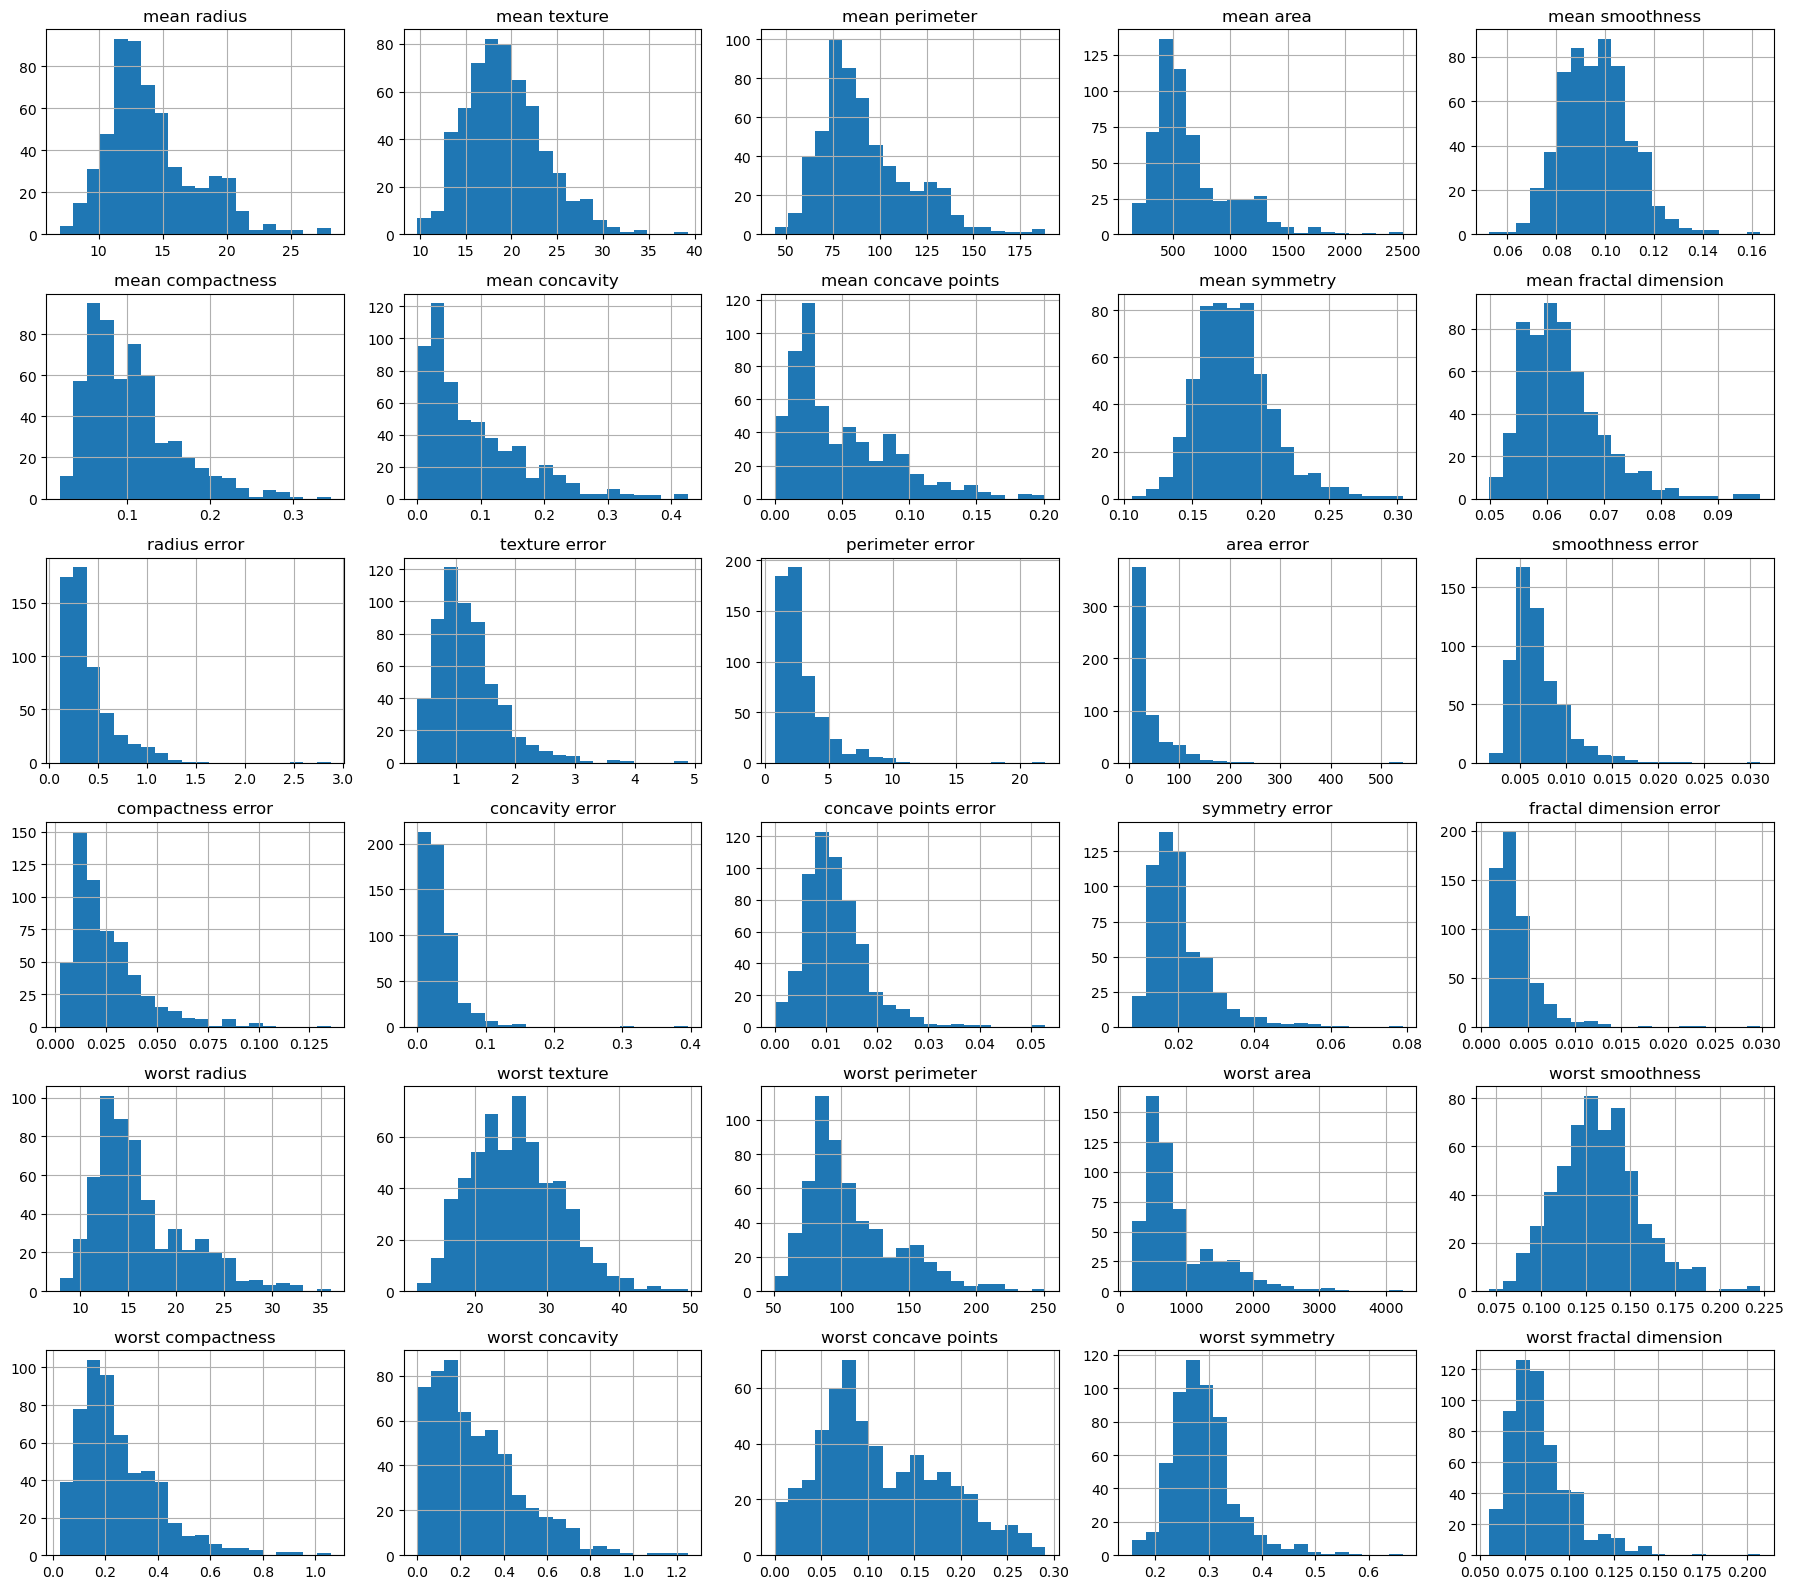

In [32]:
# feature distributions
cancer_df.drop('target', axis=1).hist(figsize=(18, 16),bins=20)

plt.tight_layout()
plt.show()

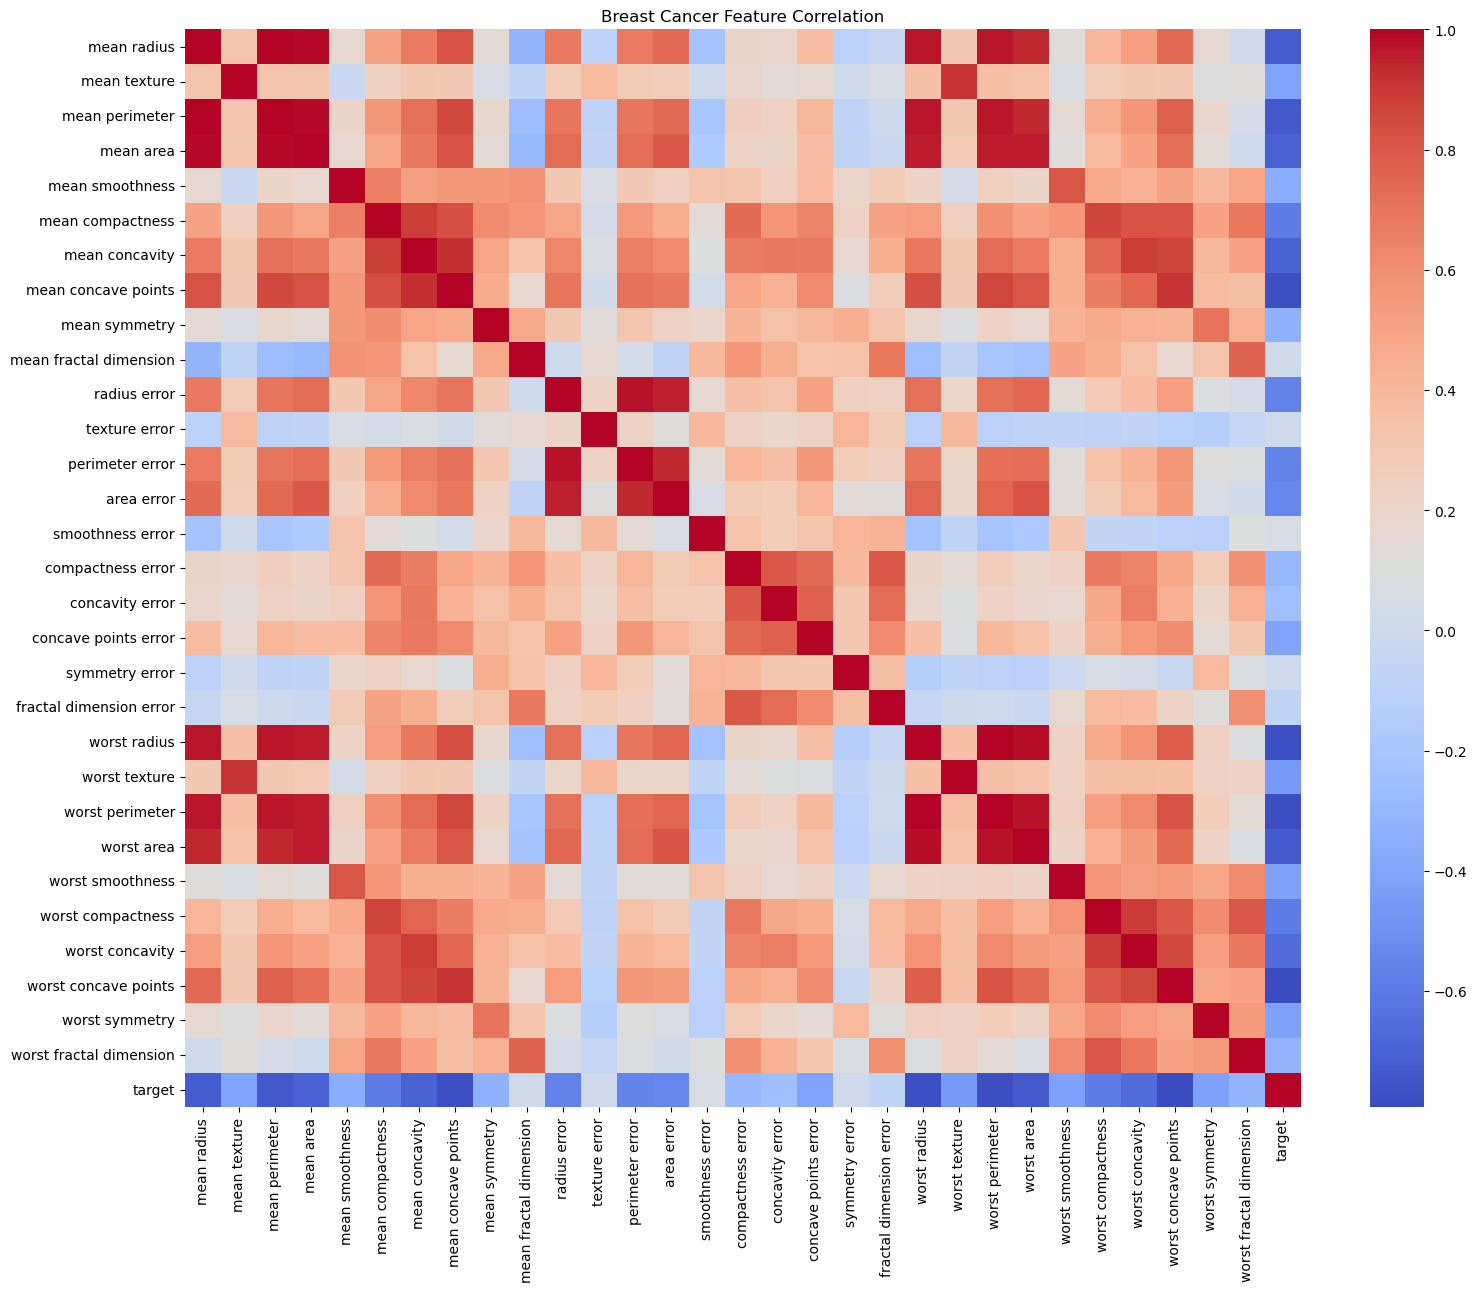

In [34]:
# correlation analysis

plt.figure(figsize=(18, 14))

sns.heatmap(cancer_df.corr(),cmap='coolwarm',annot=False)
plt.title("Breast Cancer Feature Correlation")
plt.show()

In [35]:
# Preprocessing
# Separate independent and dependent variables
X = cancer_df.drop('target', axis=1)
y = cancer_df['target']

# Check dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (569, 30)
Target shape: (569,)


In [36]:
# split data
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (455, 30)
Testing features: (114, 30)

Training target distribution:
target
1    285
0    170
Name: count, dtype: int64

Testing target distribution:
target
1    72
0    42
Name: count, dtype: int64


In [37]:
# Preview training features
X_train.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
546,10.32,16.35,65.31,324.9,0.09434,0.04994,0.01012,0.005495,0.1885,0.06201,...,11.25,21.77,71.12,384.9,0.1285,0.08842,0.04384,0.02381,0.2681,0.07399
432,20.18,19.54,133.80,1250.0,0.11330,0.14890,0.21330,0.125900,0.1724,0.06053,...,22.03,25.07,146.00,1479.0,0.1665,0.29420,0.53080,0.21730,0.3032,0.08075
174,10.66,15.15,67.49,349.6,0.08792,0.04302,0.00000,0.000000,0.1928,0.05975,...,11.54,19.20,73.20,408.3,0.1076,0.06791,0.00000,0.00000,0.2710,0.06164
221,13.56,13.90,88.59,561.3,0.10510,0.11920,0.07860,0.044510,0.1962,0.06303,...,14.98,17.13,101.10,686.6,0.1376,0.26980,0.25770,0.09090,0.3065,0.08177
289,11.37,18.89,72.17,396.0,0.08713,0.05008,0.02399,0.021730,0.2013,0.05955,...,12.36,26.14,79.29,459.3,0.1118,0.09708,0.07529,0.06203,0.3267,0.06994


In [40]:
# Modelling
# Initialize AdaBoost Classifier
from sklearn.ensemble import AdaBoostClassifier
ada_clf = AdaBoostClassifier(random_state=42)
# Train the classifier
ada_clf.fit(X_train, y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,42


In [41]:
# Training predictions
y_train_pred = ada_clf.predict(X_train)

# Testing predictions
y_test_pred = ada_clf.predict(X_test)

# Prediction probabilities
y_test_prob = ada_clf.predict_proba(X_test)[:, 1]

In [45]:
# Evaluation
from sklearn.metrics import accuracy_score
# Training performance
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))

# Testing performance
print("\nTesting Performance")
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))


Training Accuracy: 1.0

Testing Performance
Accuracy: 0.956140350877193
Precision: 0.9466666666666667
Recall: 0.9861111111111112
F1 Score: 0.9659863945578231
ROC-AUC: 0.982473544973545


In [46]:
# classification report
print(classification_report(y_test,y_test_pred,target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



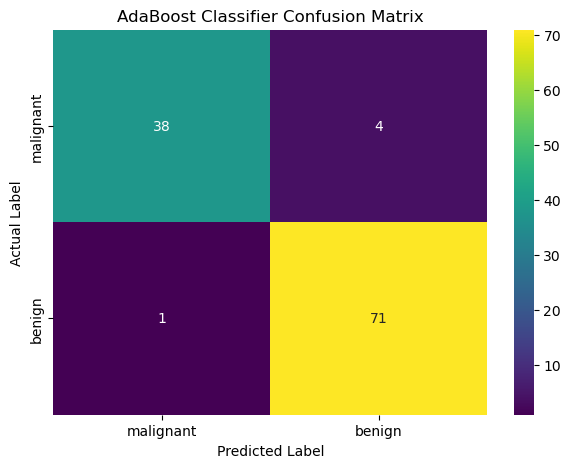

In [48]:
# confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm,annot=True,fmt='d',cmap='viridis',xticklabels=cancer.target_names,yticklabels=cancer.target_names)
plt.title("AdaBoost Classifier Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

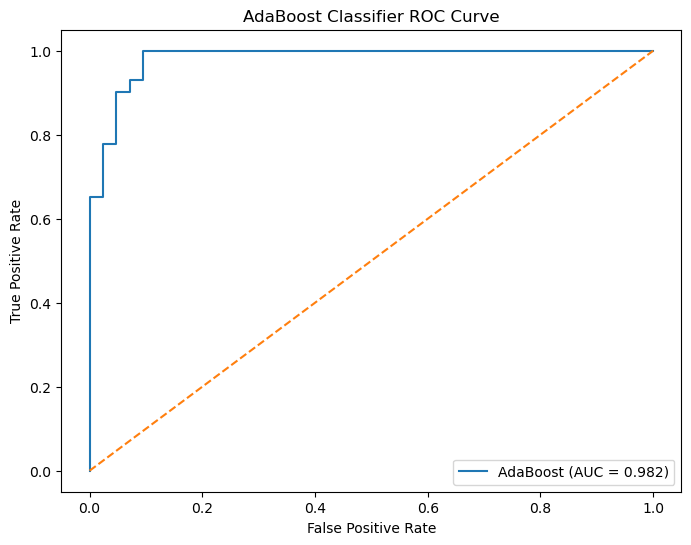

In [49]:
# ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
plt.figure(figsize=(8, 6))

plt.plot(fpr,tpr,label=f"AdaBoost (AUC = {roc_auc_score(y_test, y_test_prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("AdaBoost Classifier ROC Curve")
plt.legend()
plt.show()

In [50]:
# feature importance

ada_clf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': ada_clf.feature_importances_
}).sort_values(by='Importance', ascending=False)

ada_clf_importance.head(15)

,Feature,Importance
21,worst texture,0.124860
27,worst concave points,0.121384
13,area error,0.101582
20,worst radius,0.094089
5,mean compactness,0.062895
4,mean smoothness,0.057885
23,worst area,0.053086
24,worst smoothness,0.051761
28,worst symmetry,0.051445
1,mean texture,0.045747


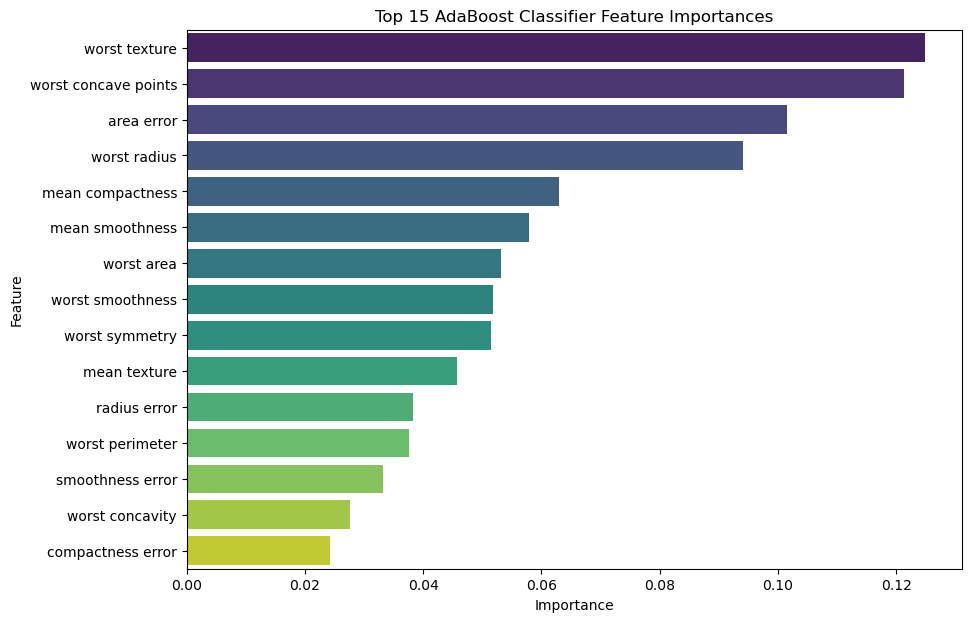

In [51]:

plt.figure(figsize=(10, 7))
sns.barplot(data=ada_clf_importance.head(15),x='Importance',y='Feature',palette='viridis')
plt.title("Top 15 AdaBoost Classifier Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [52]:
# hyperparameter tuning

param_grid_clf = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.1, 0.5, 1.0],
    'algorithm': ['SAMME']
}

ada_clf_grid = GridSearchCV(estimator=AdaBoostClassifier(random_state=42),param_grid=param_grid_clf,cv=5,scoring='f1',n_jobs=-1,verbose=1)

In [53]:
# fit search
ada_clf_grid.fit(X_train, y_train)

print("Best Parameters:", ada_clf_grid.best_params_)
print("Best Cross-Validation F1 Score:", ada_clf_grid.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'algorithm': 'SAMME', 'learning_rate': 0.5, 'n_estimators': 100}
Best Cross-Validation F1 Score: 0.9826986506746627


In [54]:
# train tuned model
ada_clf_tuned = ada_clf_grid.best_estimator_

y_train_pred_tuned = ada_clf_tuned.predict(X_train)
y_test_pred_tuned = ada_clf_tuned.predict(X_test)

y_test_prob_tuned = ada_clf_tuned.predict_proba(X_test)[:, 1]


In [55]:

print("Tuned Training Performance")
print("Accuracy:", accuracy_score(y_train, y_train_pred_tuned))

print("\nTuned Testing Performance")
print("Accuracy:", accuracy_score(y_test, y_test_pred_tuned))
print("Precision:", precision_score(y_test, y_test_pred_tuned))
print("Recall:", recall_score(y_test, y_test_pred_tuned))
print("F1 Score:", f1_score(y_test, y_test_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob_tuned))


Tuned Training Performance
Accuracy: 1.0

Tuned Testing Performance
Accuracy: 0.956140350877193
Precision: 0.9466666666666667
Recall: 0.9861111111111112
F1 Score: 0.9659863945578231
ROC-AUC: 0.9834656084656085


In [56]:
# classification report

print(classification_report(y_test,y_test_pred_tuned,target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



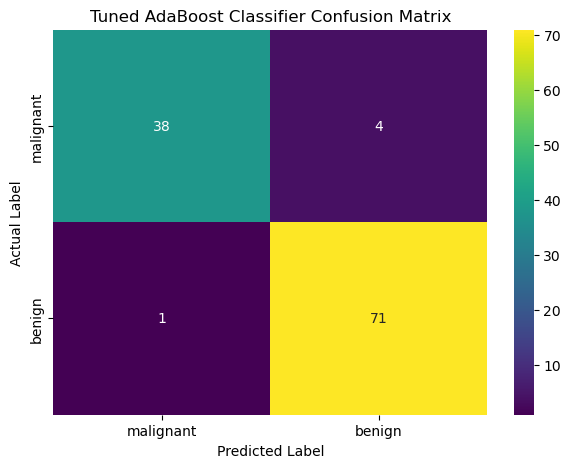

In [57]:
# confusion matrix

cm_tuned = confusion_matrix(y_test, y_test_pred_tuned)

plt.figure(figsize=(7, 5))

sns.heatmap(cm_tuned,annot=True,fmt='d',cmap='viridis',xticklabels=cancer.target_names,yticklabels=cancer.target_names)
plt.title("Tuned AdaBoost Classifier Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


In [58]:
# Original model metrics
original_metrics = [
    accuracy_score(y_test, ada_clf.predict(X_test)),
    precision_score(y_test, ada_clf.predict(X_test)),
    recall_score(y_test, ada_clf.predict(X_test)),
    f1_score(y_test, ada_clf.predict(X_test)),
    roc_auc_score(y_test, ada_clf.predict_proba(X_test)[:, 1])
]

# Tuned model metrics
tuned_metrics = [
    accuracy_score(y_test, y_test_pred_tuned),
    precision_score(y_test, y_test_pred_tuned),
    recall_score(y_test, y_test_pred_tuned),
    f1_score(y_test, y_test_pred_tuned),
    roc_auc_score(y_test, y_test_prob_tuned)
]

# Comparison DataFrame
ada_clf_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Original Model': original_metrics,
    'Tuned Model': tuned_metrics
})

ada_clf_comparison

,Metric,Original Model,Tuned Model
0,Accuracy,0.956140,0.956140
1,Precision,0.946667,0.946667
2,Recall,0.986111,0.986111
3,F1 Score,0.965986,0.965986
4,ROC-AUC,0.982474,0.983466


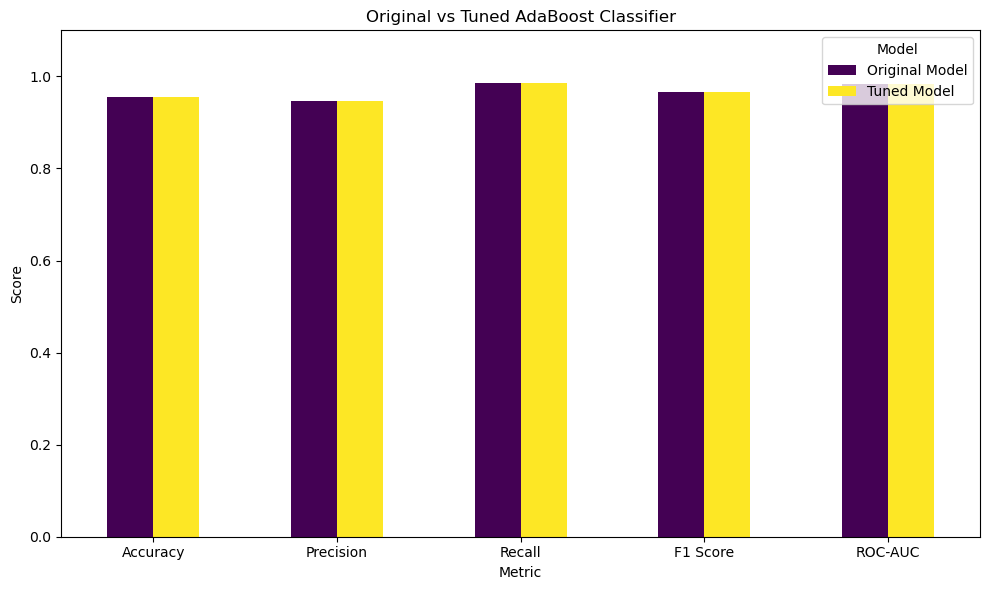

In [59]:
# visualize comparison
ada_clf_comparison.set_index('Metric').plot(kind='bar',figsize=(10, 6),colormap='viridis')

plt.title("Original vs Tuned AdaBoost Classifier")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


## Conclusion

This project explored AdaBoost (Adaptive Boosting), an ensemble machine learning algorithm used for both regression and classification tasks.

Two datasets were used to evaluate its performance:

### Regression – California Housing Dataset

The AdaBoost Regressor was trained to predict median house values.

Hyperparameter tuning improved the model's performance across all evaluation metrics:

- MAE decreased from 0.649788 to 0.580161.
- MSE decreased from 0.614478 to 0.558910.
- RMSE decreased from 0.783887 to 0.747603.
- R² increased from 0.531079 to 0.573484.

### Classification – Breast Cancer Dataset

The AdaBoost Classifier was used to classify breast tumours as malignant or benign.

The tuned model achieved:

- Accuracy: 95.61%
- Precision: 94.67%
- Recall: 98.61%
- F1 Score: 96.60%
- ROC-AUC: 98.35%

Hyperparameter tuning resulted in a slight ROC-AUC improvement, while the remaining evaluation metrics stayed unchanged.

### Overall Findings

AdaBoost demonstrated strong performance across both regression and classification tasks.

The experiments highlighted the importance of ensemble learning, sequential model training, feature importance analysis and hyperparameter optimization.

Although tuning improved regression performance considerably, its effect on classification was minimal.

The project demonstrates how AdaBoost can be applied to different predictive modelling problems and how model performance can be evaluated using appropriate metrics.
